# Pilot bằng chứng và annotation — Hohai 6-DOF

Nguồn mô hình thử nghiệm với mỗi sheet workbook là một session riêng. Roll/Pitch dùng độ; sampling 50 Hz đến từ metadata tài liệu; timestamp được suy từ chỉ số mẫu. Tên sheet/cấu hình không phải nhãn hazard.

Notebook đọc form được sinh bởi `ml.labeling.pilot` và evidence audit từ `ml.labeling.evidence_audit`; thuật toán hiển thị không được sao chép vào notebook. Không có nhãn tự động hoặc ground truth được tạo.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "ml/labeling/pilot.py").is_file():
    REPO_ROOT = next(p for p in Path.cwd().parents if (p / "ml/labeling/pilot.py").is_file())
sys.path.insert(0, str(REPO_ROOT))
from ml.labeling.evidence_audit import audit_label_evidence

ARTIFACT_ROOT = REPO_ROOT / "ml/data/labels/annotation_pilot"
FORM_PATH = ARTIFACT_ROOT / "annotation_pilot.csv"
forms = pd.read_csv(FORM_PATH, keep_default_na=False)
evidence = audit_label_evidence(REPO_ROOT, form_path=FORM_PATH)
print(f"Số hồ sơ pilot hiện có: {len(forms)}")
print(f"Số quyết định reviewer: {evidence['reviewed_decisions']}")


Số hồ sơ pilot hiện có: 92
Số quyết định reviewer: 0


## Cấu trúc mẫu và độ phủ evidence

Một cửa sổ là một mục cần con người xem xét, không phải một phiên độc lập. Metadata thử nghiệm chỉ giữ ngữ cảnh và không quyết định nhãn.

In [2]:
dataset = "hohai"
subset = forms.loc[forms.dataset_source.eq(dataset)].copy()
source_audit = evidence["datasets"][dataset]
subset["reviewed_bool"] = subset.review_status.isin(["ACCEPTED", "REJECTED", "NEEDS_DISCUSSION"])
print(f"Số mẫu: {len(subset)} | Session độc lập: {subset.session_id.nunique()}")
display(subset.groupby(["session_id", "segment_id"], as_index=False).agg(
    so_mau=("review_sample_id", "size"),
    da_review=("reviewed_bool", "sum"),
    median_context=("context_coverage_fraction", "median")))


Số mẫu: 84 | Session độc lập: 21


,session_id,segment_id,so_mau,da_review,median_context
0,Berth_B_T7_Type_A,segment_000,4,0,1.0
1,Berth_B_T8_Type_A,segment_000,4,0,1.0
2,Berth_B_T9_Type_A,segment_000,4,0,1.0
3,Berth_C_T7_Type_A,segment_000,4,0,1.0
4,Berth_C_T8_Type_A,segment_000,4,0,1.0
5,Berth_C_T9_Type_A,segment_000,4,0,1.0
6,Berth_D_T1_Type_A,segment_000,4,0,1.0
7,Berth_D_T2_Type_A,segment_000,4,0,1.0
8,Berth_D_T3_Type_A,segment_000,4,0,1.0
9,Berth_D_T3_Type_B,segment_000,4,0,1.0


## Tài liệu và giới hạn nhãn

Bảng sau là bằng chứng được kiểm kê từ nguồn và provenance. `UNVERIFIED` nghĩa là hiện chưa có chứng cứ đủ để xác nhận phenotype/hazard; không đồng nghĩa trạng thái vật lý đó không tồn tại.

In [3]:
print(evidence["evidence_conclusions"][dataset]["finding_vi"])
for claim in evidence["evidence_conclusions"][dataset]["unsupported_claims_vi"]:
    print("- " + claim)
print(f"Tham chiếu hazard vận hành đã xác minh: {source_audit['verified_operational_hazard_labels']}; " 
      f"phenotype đã được người review xác nhận: {source_audit['human_reviewed_labels']}; " 
      f"mẫu chưa review: {source_audit['pilot_samples'] - source_audit['reviewed_samples']}")


Workbook có 21 sheet/session và tên sheet chứa thông tin berth/test/type; đây là định danh cấu hình thử nghiệm, không phải nhãn trạng thái an toàn. Nguồn là mô hình thử nghiệm, thời gian suy từ 50 Hz; không có timestamp/gyro đo trực tiếp.
- Không diễn giải hậu tố Type_A/B/C thành phenotype/hazard.
- Không tuyên bố dữ liệu mô hình đại diện trực tiếp cho tàu full-scale.
Tham chiếu hazard vận hành đã xác minh: 0; phenotype đã được người review xác nhận: 0; mẫu chưa review: 84


## Kiểm tra tín hiệu thực tế

Biểu đồ hiển thị Roll/Pitch đã qua preprocessing cùng bối cảnh khả dụng trước cửa sổ và ranh giới cửa sổ 180 giây. Bối cảnh không vượt qua session/segment. Chọn mẫu có context tốt nhất để xem đủ lịch sử; bảng phía trên vẫn bao gồm mọi mẫu trong nguồn.

{'review_sample_id': 'PILOT-279f4ef04864', 'session_id': 'Berth_B_T7_Type_A', 'segment_id': 'segment_000', 'window_start_seconds': np.float64(232.0), 'window_end_seconds': np.float64(412.0), 'context_available_seconds': np.float64(180.0), 'quality_flags_json': '["FEATURE:gyro_x_abs_p95_60:MISSING_SOURCE_SIGNAL","FEATURE:gyro_x_rms_60:MISSING_SOURCE_SIGNAL","FEATURE:gyro_x_std_60:MISSING_SOURCE_SIGNAL","FEATURE:gyro_y_rms_60:MISSING_SOURCE_SIGNAL","Thời gian tương đối được suy ra từ chỉ số mẫu ở 50 Hz; không thể phát hiện dropout giữa các mẫu.","Không có gyroscope đo trực tiếp; trường gyro giữ missing.","EXPERIMENTAL_MODEL_SCALE","SAMPLE_TIME_INFERRED_FROM_50_HZ_METADATA","NO_DIRECT_GYRO","DROPOUT_NOT_VERIFIABLE_WITHOUT_TIMESTAMPS","WINDOWS_OVERLAP_BY_180S_WINDOW_AND_10S_STRIDE"]', 'experiment_metadata_json': '{"axis_sign_confidence":"medium for documented DOF labels; mounting convention unknown","original_sampling_hz":50.000000000045475,"raw_file":"6-DOF ship motions Data.xlsx","raw_re

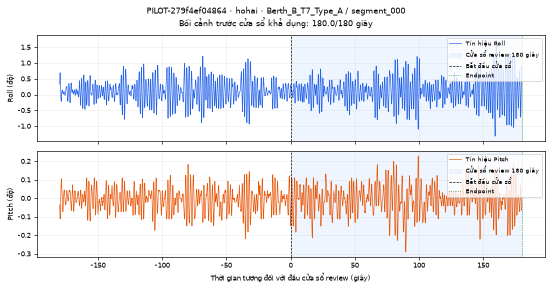

In [4]:
if subset.empty:
    raise RuntimeError("Không có mẫu pilot cho nguồn này.")
sample = subset.sort_values(["context_coverage_fraction", "window_end_seconds"], ascending=[False, True]).iloc[0]
print({key: sample[key] for key in ["review_sample_id", "session_id", "segment_id", "window_start_seconds", "window_end_seconds", "context_available_seconds", "quality_flags_json", "experiment_metadata_json"]})
display(Image(filename=str(REPO_ROOT / sample.plot_path)))


## Annotation form

Decision/evidence/reviewer fields remain empty until an actual reviewer completes them. `OBSERVED_MOTION_PHENOTYPE` only supports a human-reviewed motion observation; `VERIFIED_OPERATIONAL_HAZARD` needs an independent operational reference. `NORMAL` requires a positively accepted operating envelope.

In [5]:
form_columns = ["review_sample_id", "queue_suggested_label", "evidence_category", "evidence_reference",
                "reviewer_id", "reviewer_decision", "phenotype_flags_json", "reviewer_notes",
                "review_timestamp_utc", "review_status", "label_status", "ambiguity_reason"]
display(subset[form_columns].head(8))
print("Review thực tế đã hoàn tất:", int(subset.review_status.isin(["ACCEPTED", "REJECTED", "NEEDS_DISCUSSION"]).sum()))


,review_sample_id,queue_suggested_label,evidence_category,evidence_reference,reviewer_id,reviewer_decision,phenotype_flags_json,reviewer_notes,review_timestamp_utc,review_status,label_status,ambiguity_reason
4,PILOT-f956c9acb164,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
5,PILOT-279f4ef04864,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
6,PILOT-72e20db9cda0,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
7,PILOT-e1989c73a3da,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
8,PILOT-93fac00b3ce8,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
9,PILOT-3fd7945fc918,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
10,PILOT-886c108373a4,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,
11,PILOT-6cf46f5c7349,UNLABELED,UNVERIFIED,,,,"{""AMPLITUDE_GROWTH"": null, ""HIGH_ROLL"": null, ...",,,PENDING,UNLABELED,


Review thực tế đã hoàn tất: 0


## Giải thích kỹ thuật phục vụ vấn đáp

- **Em đã làm gì?** Đối chiếu queue với provenance và chuẩn bị tín hiệu thật kèm form, không tạo quyết định.
- **Vì sao cần context?** Một cửa sổ 180 giây có thể không cho biết xu hướng hình thành trước đó; context hỗ trợ reviewer nhưng vẫn bị chặn ở segment.
- **Phương pháp nào?** Ghép theo dataset/session/segment/endpoint và giữ metadata nguồn bên ngoài feature vector.
- **Kết quả thực nghiệm?** Các bảng/ảnh phía trên được đọc từ artifact tạo bởi pipeline; số review lấy từ trạng thái hiện tại của CSV.
- **Rủi ro nếu suy nhãn?** Góc lớn hoặc điều kiện sóng không tự chứng minh hazard; cửa sổ chồng lấn cũng không phải bằng chứng độc lập.
- **Giới hạn?** Không có reference vận hành độc lập và chưa có reviewer decision trong dữ liệu hiện tại.